# Lezione 07 — Caso Aula
## Inflazione e tassi stocastici: pricing Monte Carlo di un inflation-linked bond

**Inquadramento del caso (Prompt 1).**  
Si valuta mediante simulazione Monte Carlo un'obbligazione indicizzata all'inflazione. Il valore del contratto dipende congiuntamente da:

- il tasso istantaneo di inflazione $i_t$, modellato mediante un processo Ornstein--Uhlenbeck;
- il tasso nominale istantaneo privo di rischio $r_t$, modellato mediante un processo CIR;
- la correlazione fra gli shock dei due fattori;
- il fattore cumulato di indicizzazione $J_t$;
- il fattore di sconto $D(0,t)$;
- cedole semestrali indicizzate e rimborso del capitale protetto a scadenza.

La simulazione utilizza $M=50\,000$ **repliche Monte Carlo**, indicizzate con $k=1,\ldots,M$. Le dinamiche assegnate sono utilizzate direttamente ai fini della valutazione: non viene derivato un cambio di misura e i parametri non costituiscono una calibrazione di mercato.

L'obiettivo è costruire e verificare la catena

$$
\text{modello}
\rightarrow
\text{shock correlati}
\rightarrow
\text{traiettorie}
\rightarrow
J_t,\,D(0,t)
\rightarrow
\text{flussi}
\rightarrow
V^{(k)}
\rightarrow
\widehat V_M.
$$

Il prezzo finale deve essere interpretato come **risultato del modello assegnato**, non come quotazione osservabile di uno specifico inflation-linked bond di mercato.

# Flusso logico-teorico risolutivo

| Passo | Finalità risolutiva | Formula teorico-matematica / definizione / proprietà / teorema | Applicazione nel caso | Output o controllo collegato |
|---:|---|---|---|---|
| 1 | Fissare fattori di rischio e dipendenza | OU per \(i_t\), CIR per \(r_t\), \(dW_t^{(i)}dW_t^{(r)}=\rho\,dt\) | inflazione e tasso nominale simulati con shock correlati | coerenza dei parametri e correlazione empirica |
| 2 | Discretizzare e simulare le traiettorie | schemi discreti assegnati per OU e CIR | matrici \(M\times(N+1)\) delle traiettorie | controllo della convenzione CIR e dei valori negativi |
| 3 | Costruire l'indice di rivalutazione | \(J_t=\exp\!\left(\int_0^t i_s\,ds\right)\) | approssimazione mediante somme di Riemann lungo ogni replica | positività di \(J_t\) e statistiche di \(J_T\) |
| 4 | Costruire i fattori di sconto | \(D(0,t)=\exp\!\left(-\int_0^t r_s\,ds\right)\) | attualizzazione lungo la traiettoria del tasso della stessa replica | coerenza dei fattori di sconto |
| 5 | Costruire i flussi contrattuali | \(C_{t_j}^{(k)}=\frac c2NJ_{t_j}^{(k)}\), \(R_T^{(k)}=N\max(J_T^{(k)},1)\) | cedole semestrali indicizzate e rimborso con floor sul capitale | \(R_T^{(k)}\ge N\), probabilità di deflazione |
| 6 | Ottenere il valore per replica e il prezzo Monte Carlo | \(V^{(k)}=PV_C^{(k)}+PV_R^{(k)}\), \(\widehat V_M=M^{-1}\sum_kV^{(k)}\) | aggregazione dei flussi attualizzati | prezzo, decomposizione, SE e IC 95% |
| 7 | Valutare precisione statistica e discretizzazione | \(SE=s_V/\sqrt M\); confronto fra griglie | diagnostica al crescere di \(M\) e confronto con griglia più fine | convergenza Monte Carlo e stabilità numerica |
| 8 | Interpretare il risultato e delimitarne la portata | distinzione tra precisione Monte Carlo, discretizzazione ed errore di modello | lettura finanziaria di indicizzazione, sconto e floor | interpretazione conclusiva, limiti e riproducibilità |

## Scomposizione in sei tappe input-output (Prompt 3)

| Tappa | Regime ordinario | Input | Operazione principale | Output essenziali | Controlli principali | Uso successivo |
|---:|:---:|---|---|---|---|---|
| 1 | B | Scheda Caso, parametri, $M$, $\Delta t$, seed, $\rho$ | Definire ambiente, parametri, griglia e date contrattuali; generare gli shock correlati | Tabella parametri; griglia; matrici $Z_i,Z_r$ | Feller; dimensioni; date semestrali; correlazione empirica | Simulazione fattori |
| 2 | B | Parametri e shock correlati | Simulare $i_t$ e $r_t$ con le convenzioni numeriche assegnate | Matrici delle traiettorie; statistiche di $i_T,r_T$ | Anomalie CIR; coerenza dimensionale | Quantità path-dependent |
| 3 | B | Traiettorie $i_t,r_t$ | Costruire cumulativamente $J_t$ e $D(0,t)$ | Matrici $J,D$; statistiche $J_T$; probabilità $J_T<1$ | $J_t>0$; allineamento replica per replica | Flussi contrattuali |
| 4 | B | $J,D$, date cedolari, $N,c,T$ | Costruire cedole, rimborso e valori attuali replica per replica | $PV_C^{(k)},PV_R^{(k)},V^{(k)}$ | $R_T^{(k)}\geq N$; identità $V^{(k)}=PV_C^{(k)}+PV_R^{(k)}$ | Aggregazione Monte Carlo |
| 5 | B | Campione $V^{(k)}$ e componenti di valore | Calcolare prezzo, SE, IC 95%, decomposizione e tabelle di sintesi | $\widehat V_M$; SE; IC; tabelle di pricing e statistiche terminali | Decomposizione del prezzo | Diagnostica finale |
| 6 | B | Procedura completa e output precedenti | Costruire diagnostica per diversi $M$, confronto della griglia, grafici obbligatori e interpretazione conclusiva | Tabella diagnostica; cinque grafici; confronto $\Delta t$; conclusione | $1/\sqrt M$; stabilità temporale; coerenza complessiva; rieseguibilità | Chiusura del caso |

La Tappa 6 appartiene alla soluzione ordinaria in **Regime B**. Un eventuale Regime C avrebbe senso soltanto in presenza di una criticità specifica individuata durante il lavoro.

## Tappa 1 — Setup, griglia, date contrattuali e shock correlati

**Input.** Parametri della Scheda Caso, $M=50\,000$, $\Delta t=1/12$, seed 12345, $\rho=0.25$.  
**Operazione.** Definire la griglia mensile, i passi cedolari e generare gli shock gaussiani correlati.  
**Output.** Tabella dei parametri, calendario della simulazione, matrici $Z_i$ e $Z_r$.  
**Controlli.** Condizione di Feller, dimensioni degli array, date semestrali, correlazione empirica degli shock.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Parametri del contratto
N_nom = 100.0
T = 5.0
c = 0.015
I0 = 100.0

# Inflazione OU
i0 = 0.025
kappa_i = 0.80
theta_i = 0.020
sigma_i = 0.015

# Tasso CIR
r0 = 0.030
kappa_r = 1.20
theta_r = 0.030
sigma_r = 0.10

# Dipendenza e simulazione
rho = 0.25
dt = 1.0 / 12.0
M = 50_000
seed = 12345

n_steps = int(round(T / dt))
times = np.linspace(0.0, T, n_steps + 1)
coupon_steps = np.arange(6, n_steps + 1, 6)
coupon_times = times[coupon_steps]

params = pd.DataFrame({
    "Componente": [
        "Contratto", "Contratto", "Contratto", "Indice prezzi",
        "Inflazione OU", "Inflazione OU", "Inflazione OU", "Inflazione OU",
        "Tasso CIR", "Tasso CIR", "Tasso CIR", "Tasso CIR",
        "Dipendenza", "Simulazione", "Simulazione", "Simulazione"
    ],
    "Parametro": [
        "N", "T", "c", "I0",
        "i0", "kappa_i", "theta_i", "sigma_i",
        "r0", "kappa_r", "theta_r", "sigma_r",
        "rho", "dt", "M", "seed"
    ],
    "Valore": [
        N_nom, T, c, I0,
        i0, kappa_i, theta_i, sigma_i,
        r0, kappa_r, theta_r, sigma_r,
        rho, dt, M, seed
    ]
})

print("Tabella 1 — Parametri del caso")
display(params)

feller_lhs = 2.0 * kappa_r * theta_r
feller_rhs = sigma_r**2
feller_ok = feller_lhs >= feller_rhs
print(f"Condizione di Feller: {feller_lhs:.5f} >= {feller_rhs:.5f} -> {feller_ok}")
print(f"Griglia: {n_steps} intervalli, {n_steps + 1} nodi, dt={dt:.6f}")
print("Passi cedolari:", coupon_steps.tolist())
print("Date cedolari:", coupon_times.tolist())

rng = np.random.default_rng(seed)
Z1 = rng.standard_normal((M, n_steps))
Z2 = rng.standard_normal((M, n_steps))
Z_i = Z1
Z_r = rho * Z1 + np.sqrt(1.0 - rho**2) * Z2

rho_emp = np.corrcoef(Z_i.ravel(), Z_r.ravel())[0, 1]
print(f"Correlazione teorica degli shock: {rho:.4f}")
print(f"Correlazione empirica degli shock: {rho_emp:.4f}")
print("Shape Z_i:", Z_i.shape, "| Shape Z_r:", Z_r.shape)

Tabella 1 — Parametri del caso


,Componente,Parametro,Valore
0,Contratto,N,100.000000
1,Contratto,T,5.000000
2,Contratto,c,0.015000
3,Indice prezzi,I0,100.000000
4,Inflazione OU,i0,0.025000
5,Inflazione OU,kappa_i,0.800000
6,Inflazione OU,theta_i,0.020000
7,Inflazione OU,sigma_i,0.015000
8,Tasso CIR,r0,0.030000
9,Tasso CIR,kappa_r,1.200000


Condizione di Feller: 0.07200 >= 0.01000 -> True
Griglia: 60 intervalli, 61 nodi, dt=0.083333
Passi cedolari: [6, 12, 18, 24, 30, 36, 42, 48, 54, 60]
Date cedolari: [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]


Correlazione teorica degli shock: 0.2500
Correlazione empirica degli shock: 0.2500
Shape Z_i: (50000, 60) | Shape Z_r: (50000, 60)


## Tappa 2 — Simulazione congiunta di inflazione e tasso

**Input.** Parametri OU/CIR e shock correlati.  
**Operazione.** Simulare ricorsivamente $i_t$ e $r_t$. Nel CIR si usa $\sqrt{\max(r_t,0)}$ **soltanto nel termine diffusivo**: il nuovo valore del tasso non viene forzato a zero.  
**Output.** Matrici delle traiettorie e statistiche terminali preliminari.  
**Controlli.** Coerenza dimensionale e rilevazione di eventuali valori negativi prodotti dalla discretizzazione CIR.

In [2]:
i_paths = np.empty((M, n_steps + 1), dtype=float)
r_paths = np.empty((M, n_steps + 1), dtype=float)
i_paths[:, 0] = i0
r_paths[:, 0] = r0

for j in range(n_steps):
    i_now = i_paths[:, j]
    r_now = r_paths[:, j]

    i_paths[:, j + 1] = (
        i_now
        + kappa_i * (theta_i - i_now) * dt
        + sigma_i * np.sqrt(dt) * Z_i[:, j]
    )

    r_paths[:, j + 1] = (
        r_now
        + kappa_r * (theta_r - r_now) * dt
        + sigma_r * np.sqrt(np.maximum(r_now, 0.0)) * np.sqrt(dt) * Z_r[:, j]
    )

neg_rate_mask = r_paths < 0.0
neg_rate_count = int(neg_rate_mask.sum())
replicas_with_negative_rate = int(np.any(neg_rate_mask, axis=1).sum())

print("Shape i_paths:", i_paths.shape, "| Shape r_paths:", r_paths.shape)
print(f"Valori CIR negativi prodotti dalla discretizzazione: {neg_rate_count}")
print(f"Repliche interessate da almeno un valore CIR negativo: {replicas_with_negative_rate}")
print(f"Media i_T: {i_paths[:, -1].mean():.6f} | Dev. std i_T: {i_paths[:, -1].std(ddof=1):.6f}")
print(f"Media r_T: {r_paths[:, -1].mean():.6f} | Dev. std r_T: {r_paths[:, -1].std(ddof=1):.6f}")

Shape i_paths: (50000, 61) | Shape r_paths: (50000, 61)
Valori CIR negativi prodotti dalla discretizzazione: 2
Repliche interessate da almeno un valore CIR negativo: 2
Media i_T: 0.020121 | Dev. std i_T: 0.012102
Media r_T: 0.029934 | Dev. std r_T: 0.011422


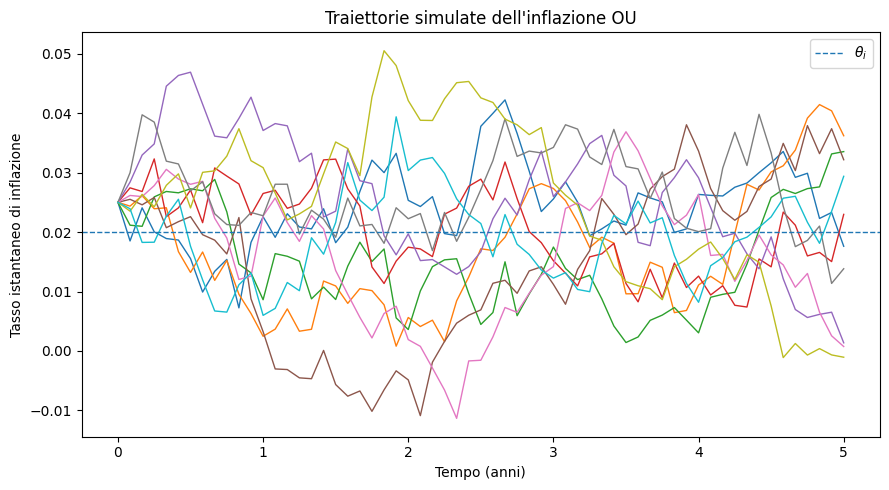

In [3]:
# Grafico 1 — alcune traiettorie simulate dell'inflazione
n_show = 10
plt.figure(figsize=(9, 5))
for k in range(n_show):
    plt.plot(times, i_paths[k, :], linewidth=1)
plt.axhline(theta_i, linestyle="--", linewidth=1, label=r"$\theta_i$")
plt.xlabel("Tempo (anni)")
plt.ylabel("Tasso istantaneo di inflazione")
plt.title("Traiettorie simulate dell'inflazione OU")
plt.legend()
plt.tight_layout()
plt.show()

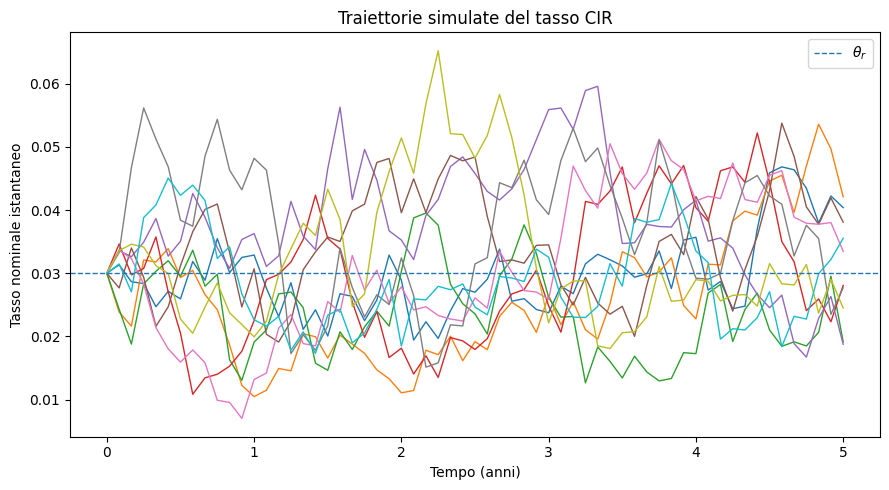

In [4]:
# Grafico 2 — alcune traiettorie simulate del tasso CIR discretizzato
plt.figure(figsize=(9, 5))
for k in range(n_show):
    plt.plot(times, r_paths[k, :], linewidth=1)
plt.axhline(theta_r, linestyle="--", linewidth=1, label=r"$\theta_r$")
plt.xlabel("Tempo (anni)")
plt.ylabel("Tasso nominale istantaneo")
plt.title("Traiettorie simulate del tasso CIR")
plt.legend()
plt.tight_layout()
plt.show()

## Tappa 3 — Costruzione di $J_t$ e $D(0,t)$

**Input.** Traiettorie simulate di inflazione e tasso.  
**Operazione.** Approssimare gli integrali temporali mediante somme di Riemann sinistre e costruire cumulativamente il fattore di indicizzazione e il fattore di sconto.  
**Output.** Matrici $J_t^{(k)}$ e $D^{(k)}(0,t)$, statistiche di $J_T$, probabilità simulata di deflazione cumulata.  
**Controlli.** $J_t^{(k)}>0$ per ogni replica e data; allineamento replica per replica.

In [5]:
# Integrali cumulati con somma di Riemann sinistra.
# La colonna 0 vale zero; per t_j si sommano i valori ai nodi 0,...,j-1.
integral_i = np.zeros_like(i_paths)
integral_r = np.zeros_like(r_paths)
integral_i[:, 1:] = np.cumsum(i_paths[:, :-1] * dt, axis=1)
integral_r[:, 1:] = np.cumsum(r_paths[:, :-1] * dt, axis=1)

J_paths = np.exp(integral_i)
D_paths = np.exp(-integral_r)

J_positive = bool(np.all(J_paths > 0.0))
J_T = J_paths[:, -1]
p_deflation = float(np.mean(J_T < 1.0))

print(f"J_t > 0 in tutte le repliche e date: {J_positive}")
print(f"Media J_T: {J_T.mean():.6f} | Dev. std J_T: {J_T.std(ddof=1):.6f}")
print(f"Probabilità simulata di deflazione cumulata P^(J_T<1): {p_deflation:.6f}")

J_t > 0 in tutte le repliche e date: True
Media J_T: 1.112638 | Dev. std J_T: 0.037504
Probabilità simulata di deflazione cumulata P^(J_T<1): 0.000780


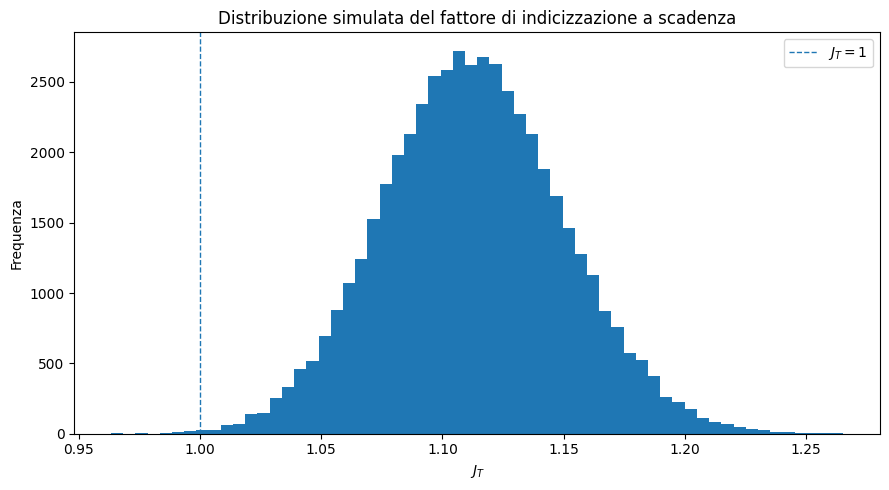

In [6]:
# Grafico 3 — distribuzione simulata di J_T
plt.figure(figsize=(9, 5))
plt.hist(J_T, bins=60)
plt.axvline(1.0, linestyle="--", linewidth=1, label=r"$J_T=1$")
plt.xlabel(r"$J_T$")
plt.ylabel("Frequenza")
plt.title("Distribuzione simulata del fattore di indicizzazione a scadenza")
plt.legend()
plt.tight_layout()
plt.show()

## Tappa 4 — Flussi contrattuali e valore attuale replica per replica

**Input.** $J_t$, $D(0,t)$, date cedolari, valore facciale e tasso cedolare.  
**Operazione.** Costruire cedole semestrali, rimborso protetto e valori attuali nella stessa replica.  
**Output.** $PV_C^{(k)}$, $PV_R^{(k)}$, $V^{(k)}$.  
**Controlli.** $R_T^{(k)}\geq N$ e identità pathwise $V^{(k)}=PV_C^{(k)}+PV_R^{(k)}$.

In [7]:
J_coupon = J_paths[:, coupon_steps]
D_coupon = D_paths[:, coupon_steps]

coupon_cashflows = (c / 2.0) * N_nom * J_coupon
PV_C = np.sum(D_coupon * coupon_cashflows, axis=1)

R_T = N_nom * np.maximum(J_T, 1.0)
PV_R = D_paths[:, -1] * R_T
V = PV_C + PV_R

floor_ok = bool(np.all(R_T >= N_nom))
pathwise_identity_ok = bool(np.allclose(V, PV_C + PV_R, rtol=0.0, atol=1e-12))

print(f"R_T >= N in tutte le repliche: {floor_ok}")
print(f"Identità pathwise V = PV_C + PV_R: {pathwise_identity_ok}")
print(f"Valore attuale medio delle cedole: {PV_C.mean():.6f}")
print(f"Valore attuale atteso del rimborso: {PV_R.mean():.6f}")

R_T >= N in tutte le repliche: True
Identità pathwise V = PV_C + PV_R: True
Valore attuale medio delle cedole: 7.336787
Valore attuale atteso del rimborso: 95.792617


## Tappa 5 — Prezzo Monte Carlo e statistiche di sintesi

**Input.** Campione dei valori $V^{(k)}$ e relative componenti.  
**Operazione.** Aggregare tra repliche soltanto dopo la costruzione dei valori pathwise; calcolare prezzo, errore standard, intervallo di confidenza e decomposizione.  
**Output.** Prezzo Monte Carlo, SE, IC 95%, Tabella 2 e Tabella 4.  
**Controllo.** Coerenza della decomposizione del prezzo.

In [8]:
price = float(V.mean())
s_V = float(V.std(ddof=1))
se = s_V / np.sqrt(M)
ci_low = price - 1.96 * se
ci_high = price + 1.96 * se
mean_PV_C = float(PV_C.mean())
mean_PV_R = float(PV_R.mean())
decomposition_ok = bool(np.isclose(price, mean_PV_C + mean_PV_R, rtol=0.0, atol=1e-12))

pricing_summary = pd.DataFrame({
    "Quantità": [
        "Valore attuale medio cedole",
        "Valore attuale atteso rimborso",
        "Prezzo Monte Carlo",
        "Errore standard",
        "IC 95% - limite inferiore",
        "IC 95% - limite superiore",
        "Probabilità simulata J_T < 1"
    ],
    "Valore": [
        mean_PV_C, mean_PV_R, price, se, ci_low, ci_high, p_deflation
    ]
})

terminal_stats = pd.DataFrame({
    "Variabile": ["i_T", "r_T", "J_T"],
    "Media": [i_paths[:, -1].mean(), r_paths[:, -1].mean(), J_T.mean()],
    "Deviazione standard": [
        i_paths[:, -1].std(ddof=1),
        r_paths[:, -1].std(ddof=1),
        J_T.std(ddof=1)
    ]
})

print("Tabella 2 — Sintesi del pricing")
display(pricing_summary)
print("Tabella 4 — Statistiche terminali")
display(terminal_stats)
print(f"Decomposizione del prezzo verificata: {decomposition_ok}")

Tabella 2 — Sintesi del pricing


,Quantità,Valore
0,Valore attuale medio cedole,7.336787
1,Valore attuale atteso rimborso,95.792617
2,Prezzo Monte Carlo,103.129404
3,Errore standard,0.016944
4,IC 95% - limite inferiore,103.096193
5,IC 95% - limite superiore,103.162615
6,Probabilità simulata J_T < 1,0.000780


Tabella 4 — Statistiche terminali


,Variabile,Media,Deviazione standard
0,i_T,0.020121,0.012102
1,r_T,0.029934,0.011422
2,J_T,1.112638,0.037504


Decomposizione del prezzo verificata: True


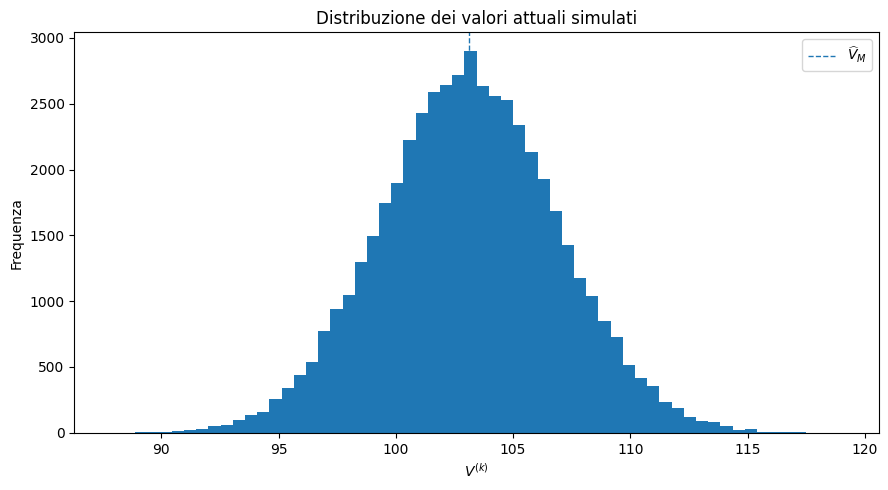

In [9]:
# Grafico 4 — distribuzione dei valori attuali per replica
plt.figure(figsize=(9, 5))
plt.hist(V, bins=60)
plt.axvline(price, linestyle="--", linewidth=1, label=r"$\widehat V_M$")
plt.xlabel(r"$V^{(k)}$")
plt.ylabel("Frequenza")
plt.title("Distribuzione dei valori attuali simulati")
plt.legend()
plt.tight_layout()
plt.show()

## Tappa 6 — Diagnostica Monte Carlo, controllo della griglia e interpretazione

**Input.** Procedura completa e output delle tappe precedenti.  
**Operazione.** Valutare la precisione al variare di $M$, verificare la stabilità rispetto a una griglia più fine, produrre il grafico di convergenza e ricomporre i controlli.  
**Output.** Tabella 3, grafico di convergenza, confronto fra griglie e interpretazione conclusiva.  
**Controlli.** Compatibilità con $SE=O(M^{-1/2})$, stabilità temporale, rieseguibilità e coerenza complessiva.

In [10]:
M_values = [1_000, 5_000, 10_000, 50_000]
rows = []
for m in M_values:
    v_m = V[:m]
    price_m = float(v_m.mean())
    se_m = float(v_m.std(ddof=1) / np.sqrt(m))
    rows.append({
        "M": m,
        "Prezzo": price_m,
        "Errore standard": se_m,
        "SE * sqrt(M)": se_m * np.sqrt(m)
    })

mc_diag = pd.DataFrame(rows)
print("Tabella 3 — Diagnostica Monte Carlo")
display(mc_diag)

# Controllo empirico qualitativo dell'ordine 1/sqrt(M):
# SE*sqrt(M) deve restare circa stabile, salvo variabilità campionaria.
ratio_cv = mc_diag["SE * sqrt(M)"].std(ddof=1) / mc_diag["SE * sqrt(M)"].mean()
print(f"Coeff. di variazione di SE*sqrt(M): {ratio_cv:.4f}")

Tabella 3 — Diagnostica Monte Carlo


,M,Prezzo,Errore standard,SE * sqrt(M)
0,1000,103.226415,0.114667,3.626076
1,5000,103.187034,0.053766,3.801860
2,10000,103.187278,0.037841,3.784057
3,50000,103.129404,0.016944,3.788863


Coeff. di variazione di SE*sqrt(M): 0.0222


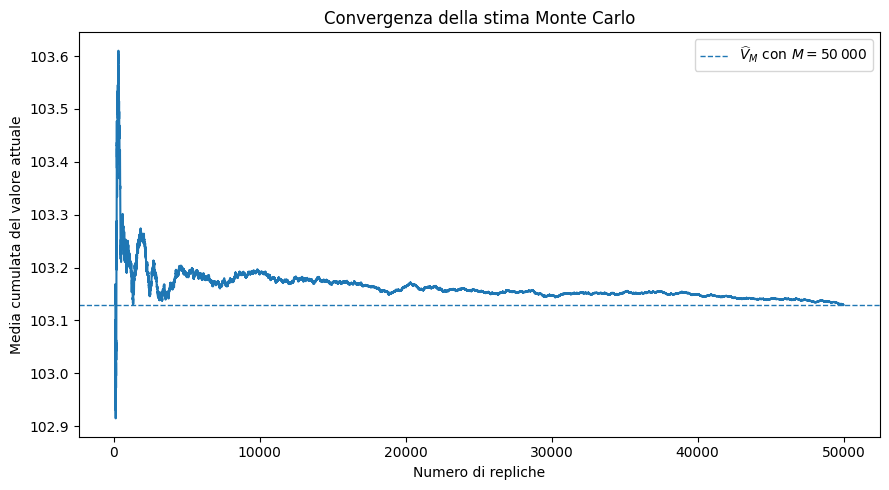

In [11]:
# Grafico 5 — convergenza della media Monte Carlo
cum_price = np.cumsum(V) / np.arange(1, M + 1)
start_plot = 100
x = np.arange(start_plot, M + 1)

plt.figure(figsize=(9, 5))
plt.plot(x, cum_price[start_plot - 1:])
plt.axhline(price, linestyle="--", linewidth=1, label=r"$\widehat V_M$ con $M=50\,000$")
plt.xlabel("Numero di repliche")
plt.ylabel("Media cumulata del valore attuale")
plt.title("Convergenza della stima Monte Carlo")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
def price_on_refined_grid_from_coarse_drivers(
    Z1_coarse, Z2_coarse, *, bridge_seed=54321, dt_fine=1.0/24.0
):
    """Prezzo su griglia più fine, accoppiato al campione mensile.

    Ogni shock mensile Z viene suddiviso in due shock standard normali
    z_a=(Z+U)/sqrt(2), z_b=(Z-U)/sqrt(2), così che
    (z_a+z_b)/sqrt(2)=Z. Il confronto riduce la componente di rumore
    Monte Carlo tra griglia base e griglia raffinata.
    """
    M_local, coarse_steps = Z1_coarse.shape
    fine_steps = 2 * coarse_steps
    rng_bridge = np.random.default_rng(bridge_seed)

    i_now = np.full(M_local, i0, dtype=float)
    r_now = np.full(M_local, r0, dtype=float)
    integral_i_now = np.zeros(M_local, dtype=float)
    integral_r_now = np.zeros(M_local, dtype=float)
    pv_c = np.zeros(M_local, dtype=float)
    neg_count = 0

    # Con dt=1/24, una cedola semestrale cade ogni 12 passi fini.
    coupon_fine_steps = set(range(12, fine_steps + 1, 12))

    fine_index = 0
    for j in range(coarse_steps):
        U1 = rng_bridge.standard_normal(M_local)
        U2 = rng_bridge.standard_normal(M_local)

        z1_a = (Z1_coarse[:, j] + U1) / np.sqrt(2.0)
        z1_b = (Z1_coarse[:, j] - U1) / np.sqrt(2.0)
        z2_a = (Z2_coarse[:, j] + U2) / np.sqrt(2.0)
        z2_b = (Z2_coarse[:, j] - U2) / np.sqrt(2.0)

        for z1_half, z2_half in ((z1_a, z2_a), (z1_b, z2_b)):
            z_i = z1_half
            z_r = rho * z1_half + np.sqrt(1.0 - rho**2) * z2_half

            # Integrali di Riemann sinistri: accumulo il valore al nodo corrente.
            integral_i_now += i_now * dt_fine
            integral_r_now += r_now * dt_fine

            i_next = (
                i_now
                + kappa_i * (theta_i - i_now) * dt_fine
                + sigma_i * np.sqrt(dt_fine) * z_i
            )
            r_next = (
                r_now
                + kappa_r * (theta_r - r_now) * dt_fine
                + sigma_r * np.sqrt(np.maximum(r_now, 0.0)) * np.sqrt(dt_fine) * z_r
            )
            neg_count += int(np.sum(r_next < 0.0))

            i_now = i_next
            r_now = r_next
            fine_index += 1

            if fine_index in coupon_fine_steps:
                J_now = np.exp(integral_i_now)
                D_now = np.exp(-integral_r_now)
                coupon = (c / 2.0) * N_nom * J_now
                pv_c += D_now * coupon

    J_T_fine = np.exp(integral_i_now)
    D_T_fine = np.exp(-integral_r_now)
    R_T_fine = N_nom * np.maximum(J_T_fine, 1.0)
    V_fine = pv_c + D_T_fine * R_T_fine
    return float(V_fine.mean()), float(V_fine.std(ddof=1) / np.sqrt(M_local)), neg_count

price_fine, se_fine, neg_fine = price_on_refined_grid_from_coarse_drivers(Z1, Z2)

grid_compare = pd.DataFrame({
    "Griglia": ["Base", "Più fine"],
    "dt": [1/12, 1/24],
    "Prezzo": [price, price_fine],
    "Errore standard": [se, se_fine]
})

display(grid_compare)
print(f"Differenza prezzo (dt=1/24 - dt=1/12): {price_fine - price:.6f}")
print(f"Valori CIR negativi rilevati sulla griglia più fine: {neg_fine}")

,Griglia,dt,Prezzo,Errore standard
0,Base,0.083333,103.129404,0.016944
1,Più fine,0.041667,103.127905,0.016920


Differenza prezzo (dt=1/24 - dt=1/12): -0.001499
Valori CIR negativi rilevati sulla griglia più fine: 0


In [13]:
# Quadro finale dei controlli obbligatori
checks = pd.DataFrame({
    "Controllo": [
        "Correlazione empirica degli shock compatibile con rho",
        "J_t > 0 per ogni replica e data",
        "R_T >= N per ogni replica",
        "Valori CIR negativi rilevati senza flooring del nuovo valore",
        "Decomposizione del prezzo",
        "SE compatibile con ordine 1/sqrt(M)",
        "Confronto con griglia più fine eseguito"
    ],
    "Esito": [
        abs(rho_emp - rho) < 0.01,
        J_positive,
        floor_ok,
        True,  # il notebook li rileva e li conta; il test non richiede che siano presenti
        decomposition_ok and pathwise_identity_ok,
        ratio_cv < 0.10,
        np.isfinite(price_fine)
    ]
})
print("Sintesi dei controlli")
display(checks)

Sintesi dei controlli


,Controllo,Esito
0,Correlazione empirica degli shock compatibile ...,True
1,J_t > 0 per ogni replica e data,True
2,R_T >= N per ogni replica,True
3,Valori CIR negativi rilevati senza flooring de...,True
4,Decomposizione del prezzo,True
5,SE compatibile con ordine 1/sqrt(M),True
6,Confronto con griglia più fine eseguito,True


In [14]:
# Interpretazione conclusiva, generata dagli output del notebook per restare rieseguibile.
protection_share = float(np.mean(J_T < 1.0))
text = f"""
## Interpretazione finanziaria conclusiva

La simulazione produce un prezzo Monte Carlo pari a **{price:.4f}**, con errore standard **{se:.4f}** e intervallo di confidenza Monte Carlo al 95% **[{ci_low:.4f}, {ci_high:.4f}]**.

Il valore si scompone in un valore attuale medio delle cedole pari a **{mean_PV_C:.4f}** e in un valore attuale atteso del rimborso pari a **{mean_PV_R:.4f}**. La costruzione è effettuata replica per replica: l'indicizzazione determina cedole e capitale, mentre la traiettoria del tasso nominale determina i fattori di sconto applicati ai flussi della stessa replica.

La probabilità simulata di deflazione cumulata a scadenza è **{protection_share:.4%}**. In queste repliche il floor sul capitale impedisce che il rimborso scenda sotto il valore facciale; le cedole, invece, non sono protette dallo stesso floor.

Il confronto numerico fra la griglia mensile e la griglia più fine produce una differenza di prezzo pari a **{price_fine - price:.4f}**. Questo controllo riguarda l'approssimazione temporale ed è distinto dalla precisione Monte Carlo, misurata dall'errore standard e dal suo andamento al crescere di $M$.

Il valore ottenuto deve essere interpretato come **risultato delle dinamiche e dei parametri assegnati nel caso**. I parametri non sono calibrati al mercato e non viene derivato un cambio di misura; il risultato non coincide quindi con la quotazione osservabile di uno specifico inflation-linked bond di mercato.
"""
display(Markdown(text))


## Interpretazione finanziaria conclusiva

La simulazione produce un prezzo Monte Carlo pari a **103.1294**, con errore standard **0.0169** e intervallo di confidenza Monte Carlo al 95% **[103.0962, 103.1626]**.

Il valore si scompone in un valore attuale medio delle cedole pari a **7.3368** e in un valore attuale atteso del rimborso pari a **95.7926**. La costruzione è effettuata replica per replica: l'indicizzazione determina cedole e capitale, mentre la traiettoria del tasso nominale determina i fattori di sconto applicati ai flussi della stessa replica.

La probabilità simulata di deflazione cumulata a scadenza è **0.0780%**. In queste repliche il floor sul capitale impedisce che il rimborso scenda sotto il valore facciale; le cedole, invece, non sono protette dallo stesso floor.

Il confronto numerico fra la griglia mensile e la griglia più fine produce una differenza di prezzo pari a **-0.0015**. Questo controllo riguarda l'approssimazione temporale ed è distinto dalla precisione Monte Carlo, misurata dall'errore standard e dal suo andamento al crescere di $M$.

Il valore ottenuto deve essere interpretato come **risultato delle dinamiche e dei parametri assegnati nel caso**. I parametri non sono calibrati al mercato e non viene derivato un cambio di misura; il risultato non coincide quindi con la quotazione osservabile di uno specifico inflation-linked bond di mercato.


## Limiti del modello e riproducibilità

Il caso utilizza parametri costanti e assegnati a fini didattici. Non vengono introdotti calibrazione di mercato, rischio di credito, liquidità o fiscalità; l'indicizzazione è semplificata rispetto alle convenzioni operative di titoli inflation-linked reali. OU e CIR sono modelli formulati in tempo continuo, mentre il notebook ne utilizza rappresentazioni discretizzate.

La precisione Monte Carlo, l'approssimazione temporale e l'errore di modello devono quindi restare concettualmente distinti.

Il notebook è costruito per essere eseguito integralmente dall'inizio. Il campione principale utilizza il seed **12345**; il confronto sulla griglia più fine usa gli stessi driver mensili, suddivisi tramite un Brownian bridge con seed separato e fissato, così da rendere anche il controllo di discretizzazione riproducibile.

La sequenza finale resta ricostruibile:

$$
\text{ipotesi}
\rightarrow
\text{simulazione}
\rightarrow
\text{quantità contrattuali}
\rightarrow
\text{flussi}
\rightarrow
\text{valore}
\rightarrow
\text{controlli}
\rightarrow
\text{interpretazione}.
$$